# FT-Transformer on Jannis & Higgs

- Paper: [Revisiting Deep Learning Models for Tabular Data](https://arxiv.org/html/2106.11959v5)


| Dataset | OpenML link | Paper test accuracy (FT-Transformer, tuned, 15 seeds) |
|---|---|---|
| Higgs Small (98,050 ) | https://www.openml.org/d/23512 | **0.729** |

In [1]:
# %pip install scipy pandas scikit-learn

In [2]:
# %pip install torch --index-url https://download.pytorch.org/whl/cu128

In [3]:
import time
import json
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import torch


In [4]:
from sklearn.datasets import fetch_openml

# Dataset configuration to download from OpenML
DATASET_ID = 23512
DATA_DIR = Path("../data")
DATA_PATH = DATA_DIR / "higgs_small.csv"
DATA_FRAME = None

# Create directory if it does not exist
DATA_DIR.mkdir(parents=True, exist_ok=True)

if DATA_PATH.is_file():
    print("Dataset found locally.")
    print("Loading dataset...")

    DATA_FRAME = pd.read_csv(DATA_PATH)

else: 
    print("Dataset not found locally.")
    print("Downloading Higgs Small from OpenML...")

    dataset = fetch_openml(
        data_id=DATASET_ID,
        as_frame=True
    )

    DATA_FRAME = dataset.frame

    # Save dataset as CSV
    DATA_FRAME.to_csv(DATA_PATH, index=False)

    print("Dataset downloaded and saved successfully!")

Dataset found locally.
Loading dataset...


In [5]:
# Validate dataset dimensions
if DATA_FRAME.shape != (98050, 29):
    raise ValueError("Dataset shape does not match expected dimensions!") 

# Display dataset information
print("\n" + "=" * 50)
print("Dataset Information")
print("=" * 50)

print(f"File Path     : {DATA_PATH.resolve()}")
print(f"Samples       : {DATA_FRAME.shape[0]:,}")
print(f"Features      : {DATA_FRAME.shape[1] - 1}")
print(f"Missing Values: {DATA_FRAME.isnull().sum().sum()}")
print(f"File Size     : {DATA_PATH.stat().st_size / 1024**2:.2f} MB")
print(f"Duplicate Rows : {DATA_FRAME.duplicated().sum()}")
print(f"{DATA_FRAME.info()}")


missing = DATA_FRAME.isnull().sum()

display(missing[missing > 0])

display(DATA_FRAME.head())


Dataset Information
File Path     : /home/racoon/Downloads/Deep-Tabular-project/data/higgs_small.csv
Samples       : 98,050
Features      : 28
Missing Values: 9
File Size     : 43.75 MB
Duplicate Rows : 25
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 98050 entries, 0 to 98049
Data columns (total 29 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   class                     98050 non-null  int64  
 1   lepton_pT                 98050 non-null  float64
 2   lepton_eta                98050 non-null  float64
 3   lepton_phi                98050 non-null  float64
 4   missing_energy_magnitude  98050 non-null  float64
 5   missing_energy_phi        98050 non-null  float64
 6   jet1pt                    98050 non-null  float64
 7   jet1eta                   98050 non-null  float64
 8   jet1phi                   98050 non-null  float64
 9   jet1b-tag                 98050 non-null  float64
 10  jet2pt             

jet4phi      1
jet4b-tag    1
m_jj         1
m_jjj        1
m_lv         1
m_jlv        1
m_bb         1
m_wbb        1
m_wwbb       1
dtype: int64

,class,lepton_pT,lepton_eta,lepton_phi,missing_energy_magnitude,missing_energy_phi,jet1pt,jet1eta,jet1phi,jet1b-tag,...,jet4eta,jet4phi,jet4b-tag,m_jj,m_jjj,m_lv,m_jlv,m_bb,m_wbb,m_wwbb
0,1,0.907542,0.329147,0.359412,1.497970,-0.313010,1.095531,-0.557525,-1.588230,2.173076,...,-1.138930,-0.000819,0.000000,0.302220,0.833048,0.985700,0.978098,0.779732,0.992356,0.798343
1,1,0.798835,1.470639,-1.635975,0.453773,0.425629,1.104875,1.282322,1.381664,0.000000,...,1.128848,0.900461,0.000000,0.909753,1.108330,0.985692,0.951331,0.803252,0.865924,0.780118
2,0,1.344385,-0.876626,0.935913,1.992050,0.882454,1.786066,-1.646778,-0.942383,0.000000,...,-0.678379,-1.360356,0.000000,0.946652,1.028704,0.998656,0.728281,0.869200,1.026736,0.957904
3,1,1.105009,0.321356,1.522401,0.882808,-1.205349,0.681466,-1.070464,-0.921871,0.000000,...,-0.373566,0.113041,0.000000,0.755856,1.361057,0.986610,0.838085,1.133295,0.872245,0.808487
4,0,1.595839,-0.607811,0.007075,1.818450,-0.111906,0.847550,-0.566437,1.581239,2.173076,...,-0.654227,-1.274345,3.101961,0.823761,0.938191,0.971758,0.789176,0.430553,0.961357,0.957818


In [6]:
missing_rows = DATA_FRAME[DATA_FRAME.isnull().any(axis=1)]

display(missing_rows)

print("Missing Rows:", len(missing_rows))
print("Missing Values:", DATA_FRAME.isnull().sum().sum())

,class,lepton_pT,lepton_eta,lepton_phi,missing_energy_magnitude,missing_energy_phi,jet1pt,jet1eta,jet1phi,jet1b-tag,...,jet4eta,jet4phi,jet4b-tag,m_jj,m_jjj,m_lv,m_jlv,m_bb,m_wbb,m_wwbb
98049,1,0.708611,1.190136,0.593008,1.899366,-0.111872,0.871276,0.982283,-1.684691,2.173076,...,1.797605,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Missing Rows: 1
Missing Values: 9


## Data Preprocessing


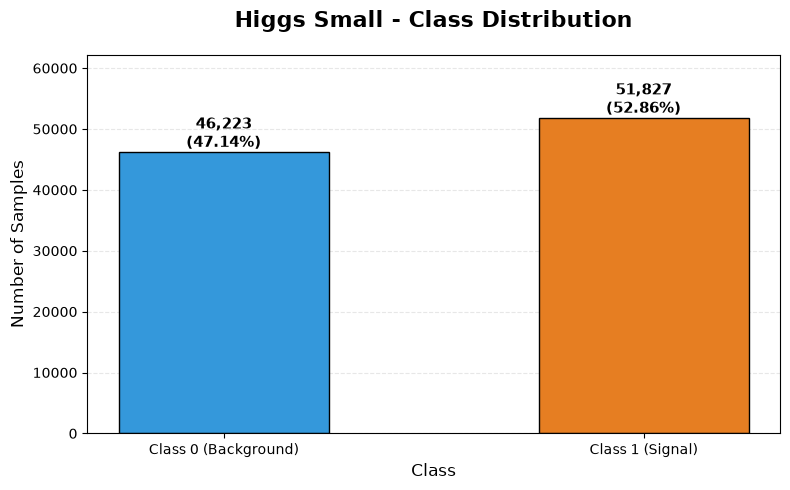

In [7]:
# Calculate class distribution
class_counts = DATA_FRAME["class"].value_counts().sort_index()

class_percentages = (
    class_counts / len(DATA_FRAME)
) * 100

# Create figure
fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    ["Class 0 (Background)", "Class 1 (Signal)"],
    class_counts,
    color=["#3498db", "#e67e22"],
    width=0.5,
    edgecolor="black"
)

# Add count and percentage labels
for bar, count, percentage in zip(
    bars, class_counts, class_percentages
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{count:,}\n({percentage:.2f}%)",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

# Chart configuration
ax.set_title(
    "Higgs Small - Class Distribution",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Class", fontsize=12)
ax.set_ylabel("Number of Samples", fontsize=12)

ax.set_ylim(0, class_counts.max() * 1.2)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

In [8]:
TOTAL_SAMPLES = len(DATA_FRAME)
DUPLICATE_COUNT = DATA_FRAME.duplicated().sum()

DUPLICATE_PERCENTAGE = (
    DUPLICATE_COUNT / TOTAL_SAMPLES
) * 100

print(f"Total Samples       : {TOTAL_SAMPLES:,}")
print(f"Duplicate Rows      : {DUPLICATE_COUNT}")
print(f"Unique Rows         : {TOTAL_SAMPLES - DUPLICATE_COUNT:,}")
print(f"Duplicate Percentage: {DUPLICATE_PERCENTAGE:.4f}%")

Total Samples       : 98,050
Duplicate Rows      : 25
Unique Rows         : 98,025
Duplicate Percentage: 0.0255%


In [9]:
from sklearn.model_selection import train_test_split


X = DATA_FRAME.drop(columns=["class"])
y = DATA_FRAME["class"]

SEED = 0

# 80% Train + Validation, 20% Test
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

# 64% Train, 16% Validation
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.20,
    random_state=SEED,
    stratify=y_train_val
)

In [10]:
split_summary = pd.DataFrame({
    "Dataset": ["Train", "Validation", "Test"],

    "Samples": [
        len(X_train),
        len(X_val),
        len(X_test)
    ],

    "Features": [
        X_train.shape[1],
        X_val.shape[1],
        X_test.shape[1]
    ],

    "Percentage (%)": [
        len(X_train) / len(DATA_FRAME) * 100,
        len(X_val) / len(DATA_FRAME) * 100,
        len(X_test) / len(DATA_FRAME) * 100
    ],

    "Missing Values": [
        X_train.isna().sum().sum(),
        X_val.isna().sum().sum(),
        X_test.isna().sum().sum()
    ]
})

display(split_summary)

,Dataset,Samples,Features,Percentage (%),Missing Values
0,Train,62752,28,64.0,9
1,Validation,15688,28,16.0,0
2,Test,19610,28,20.0,0


In [11]:
DUPLICATE_SUMMARY = pd.DataFrame({

    "Dataset": ["Full Dataset", "Train", "Validation", "Test"],

    "Samples": [
        len(DATA_FRAME),
        len(X_train),
        len(X_val),
        len(X_test)
    ],

    "Duplicate Features": [
        X.duplicated().sum(),
        X_train.duplicated().sum(),
        X_val.duplicated().sum(),
        X_test.duplicated().sum()
    ]

})

display(DUPLICATE_SUMMARY)

,Dataset,Samples,Duplicate Features
0,Full Dataset,98050,25
1,Train,62752,9
2,Validation,15688,1
3,Test,19610,1


In [12]:
# Mean from the training data
TRAIN_MEANS = X_train.mean()


# Replace missing values using mean
X_train = X_train.fillna(TRAIN_MEANS)
X_val = X_val.fillna(TRAIN_MEANS)
X_test = X_test.fillna(TRAIN_MEANS)


print("Train Missing Values:", X_train.isna().sum().sum())
print("Validation Missing Values:", X_val.isna().sum().sum())
print("Test Missing Values:", X_test.isna().sum().sum())

Train Missing Values: 0
Validation Missing Values: 0
Test Missing Values: 0


### Quantile Normalization.

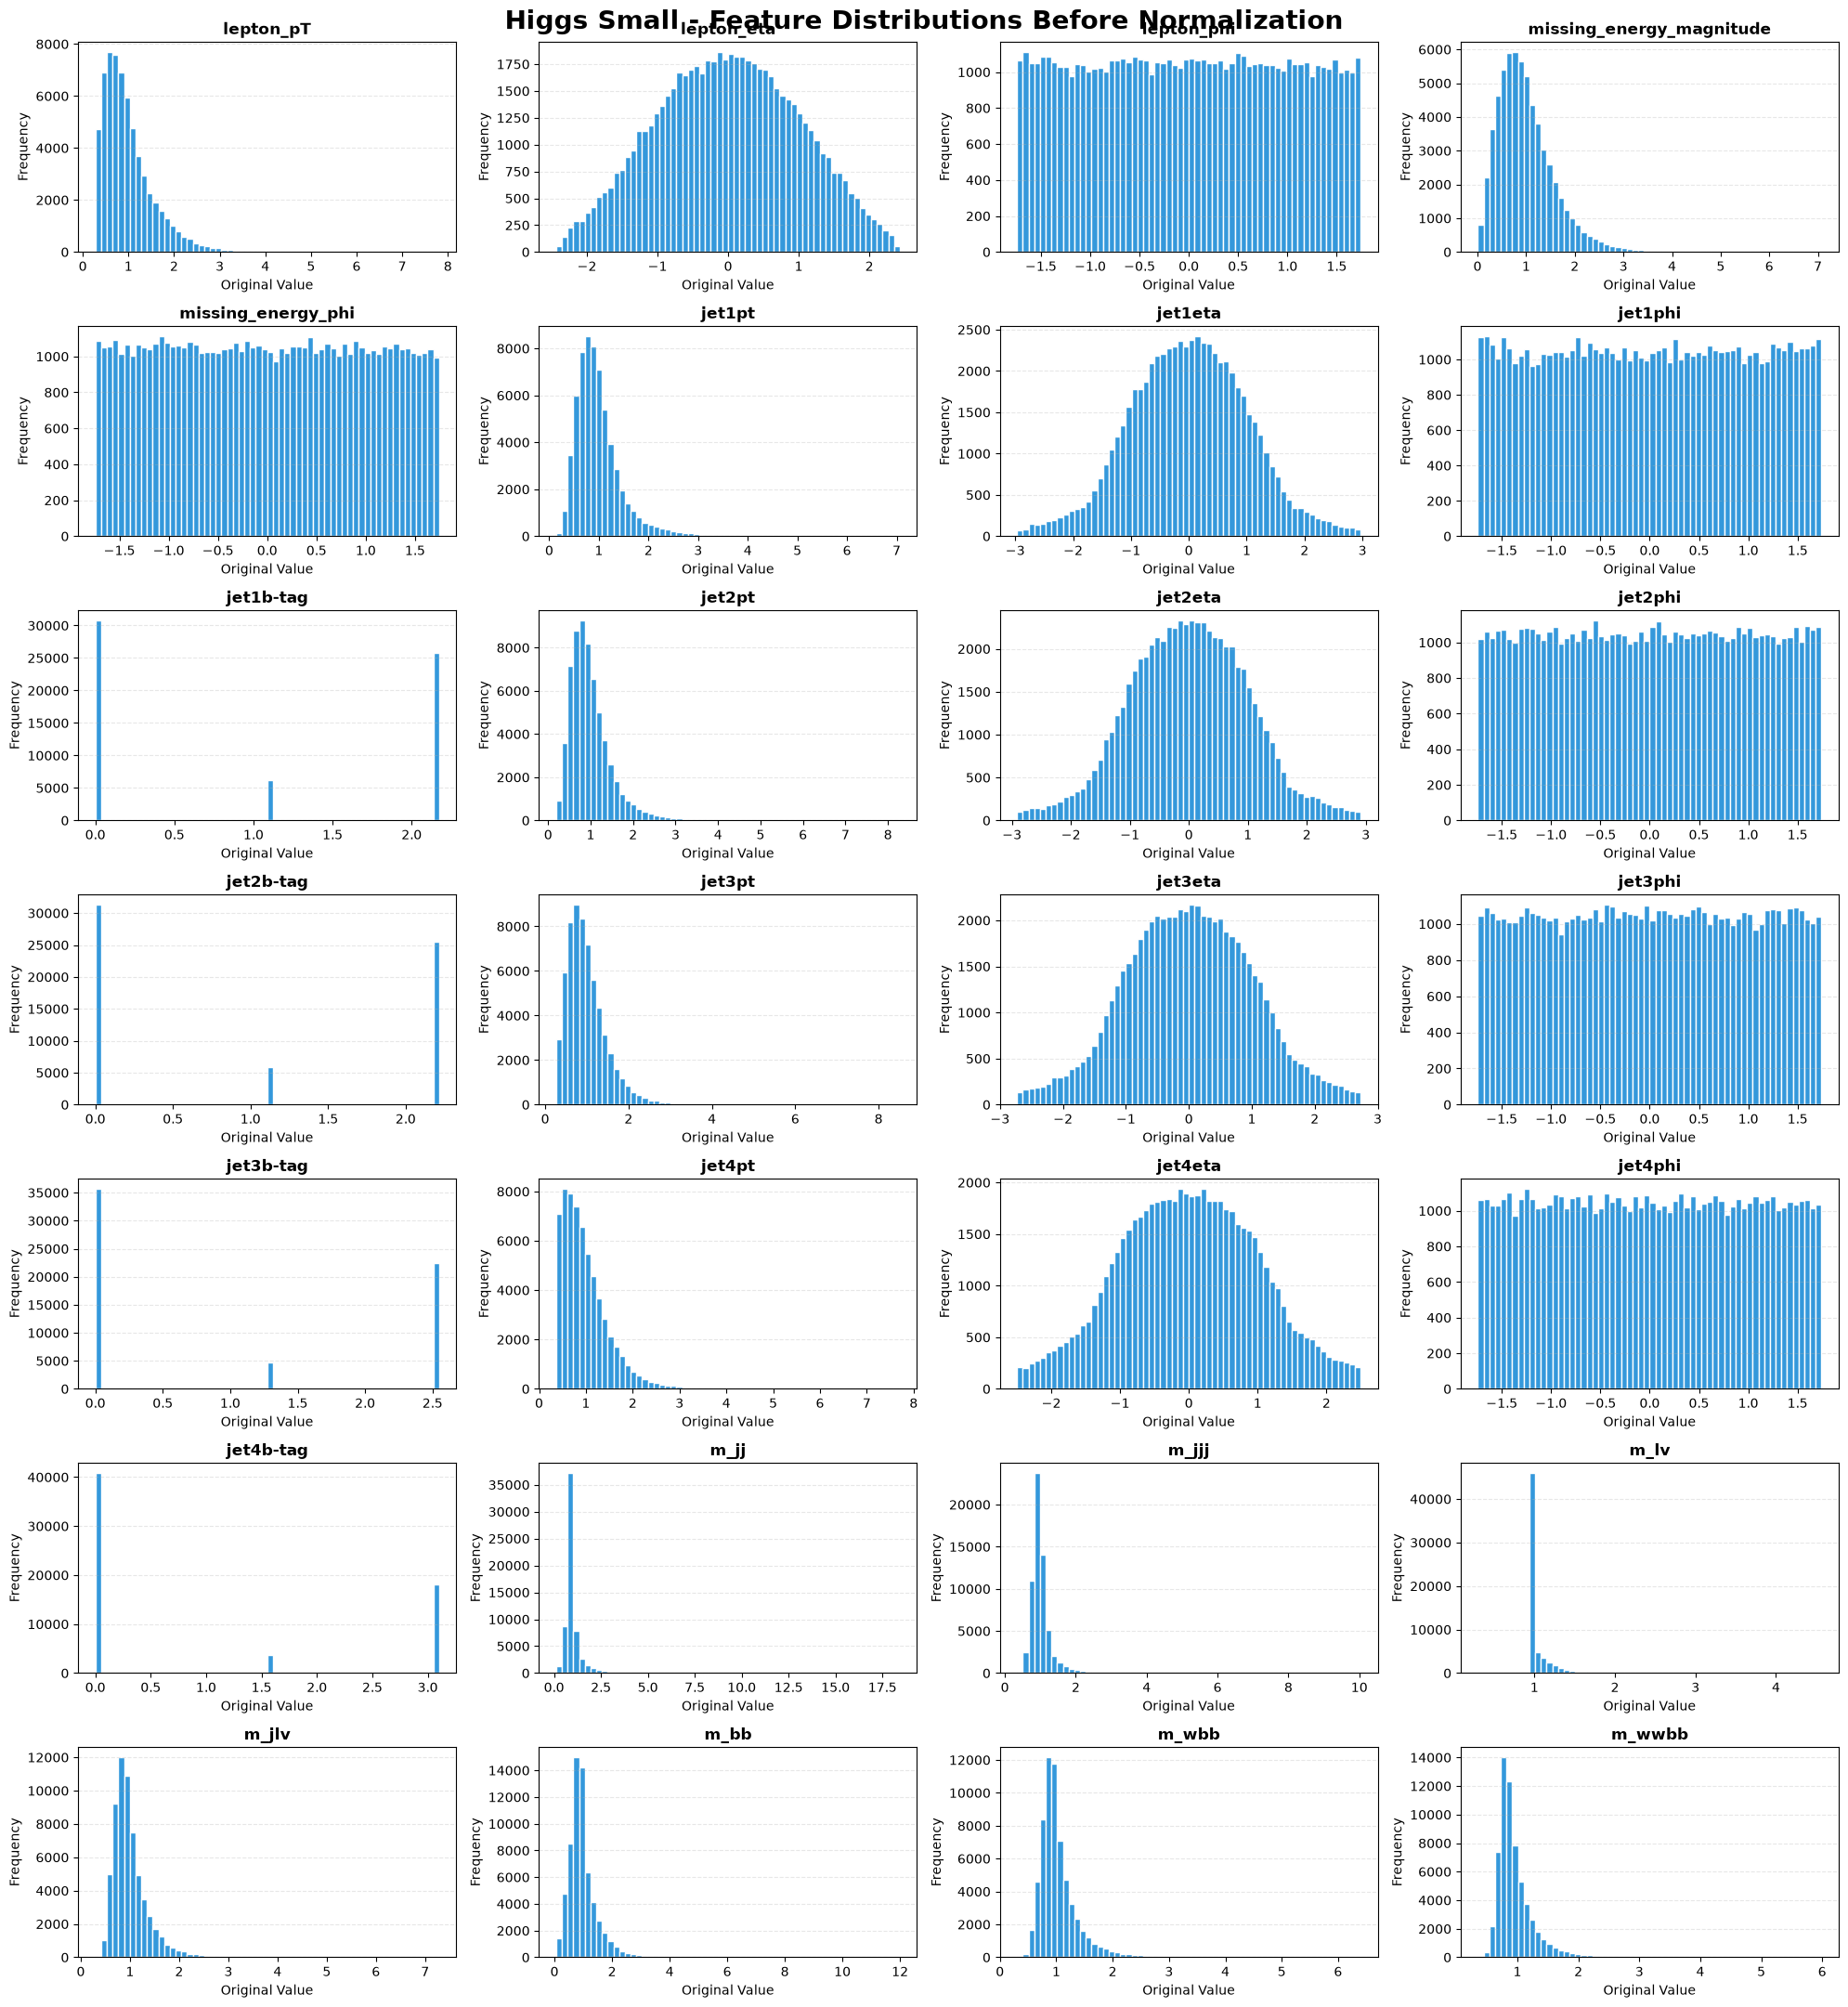

In [13]:
FEATURE_NAMES = X_train.columns.tolist()
N_FEATURES = len(FEATURE_NAMES)

fig, axes = plt.subplots(7, 4, figsize=(20, 22))

axes = axes.flatten()

for i, feature in enumerate(FEATURE_NAMES):

    axes[i].hist(
        X_train[feature],
        bins=60,
        color="#3498db",
        edgecolor="white"
    )

    axes[i].set_title(feature, fontweight="bold")
    axes[i].set_xlabel("Original Value")
    axes[i].set_ylabel("Frequency")
    axes[i].grid(axis="y", linestyle="--", alpha=0.3)

fig.suptitle(
    "Higgs Small - Feature Distributions Before Normalization",
    fontsize=20,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [14]:
from sklearn.preprocessing import QuantileTransformer

# Normalization configuration
NOISE = 1e-3

# Convert training data to NumPy
X_fit = X_train.to_numpy(dtype=np.float32).copy()

# Calculate number of quantiles
N_QUANTILES = max(
    min(len(X_fit) // 30, 1000),
    10
)

# Calculate feature standard deviations
stds = np.std(
    X_fit,
    axis=0,
    keepdims=True
)

# Calculate noise scale
noise_std = NOISE / np.maximum(stds, NOISE)

# Add Gaussian noise to fitting data only
rng = np.random.default_rng(SEED)

X_fit += noise_std * rng.standard_normal(X_fit.shape)

# Initialize Quantile Transformer
NORMALIZER = QuantileTransformer(
    n_quantiles=N_QUANTILES,
    output_distribution="normal",
    subsample=int(1e9),
    random_state=SEED
)

# Fit using training data only
NORMALIZER.fit(X_fit)

# Transform all dataset splits
X_train_norm = NORMALIZER.transform(
    X_train.to_numpy(dtype=np.float32)
)

X_val_norm = NORMALIZER.transform(
    X_val.to_numpy(dtype=np.float32)
)

X_test_norm = NORMALIZER.transform(
    X_test.to_numpy(dtype=np.float32)
)

print("=" * 50)
print("Quantile Normalization Completed")
print("=" * 50)

print(f"Number of Quantiles : {N_QUANTILES}")
print(f"Noise Level         : {NOISE}")
print(f"Output Distribution : normal")
print(f"Random Seed         : {SEED}")

print(f"\nTrain Shape      : {X_train_norm.shape}")
print(f"Validation Shape : {X_val_norm.shape}")
print(f"Test Shape       : {X_test_norm.shape}")

Quantile Normalization Completed
Number of Quantiles : 1000
Noise Level         : 0.001
Output Distribution : normal
Random Seed         : 0

Train Shape      : (62752, 28)
Validation Shape : (15688, 28)
Test Shape       : (19610, 28)


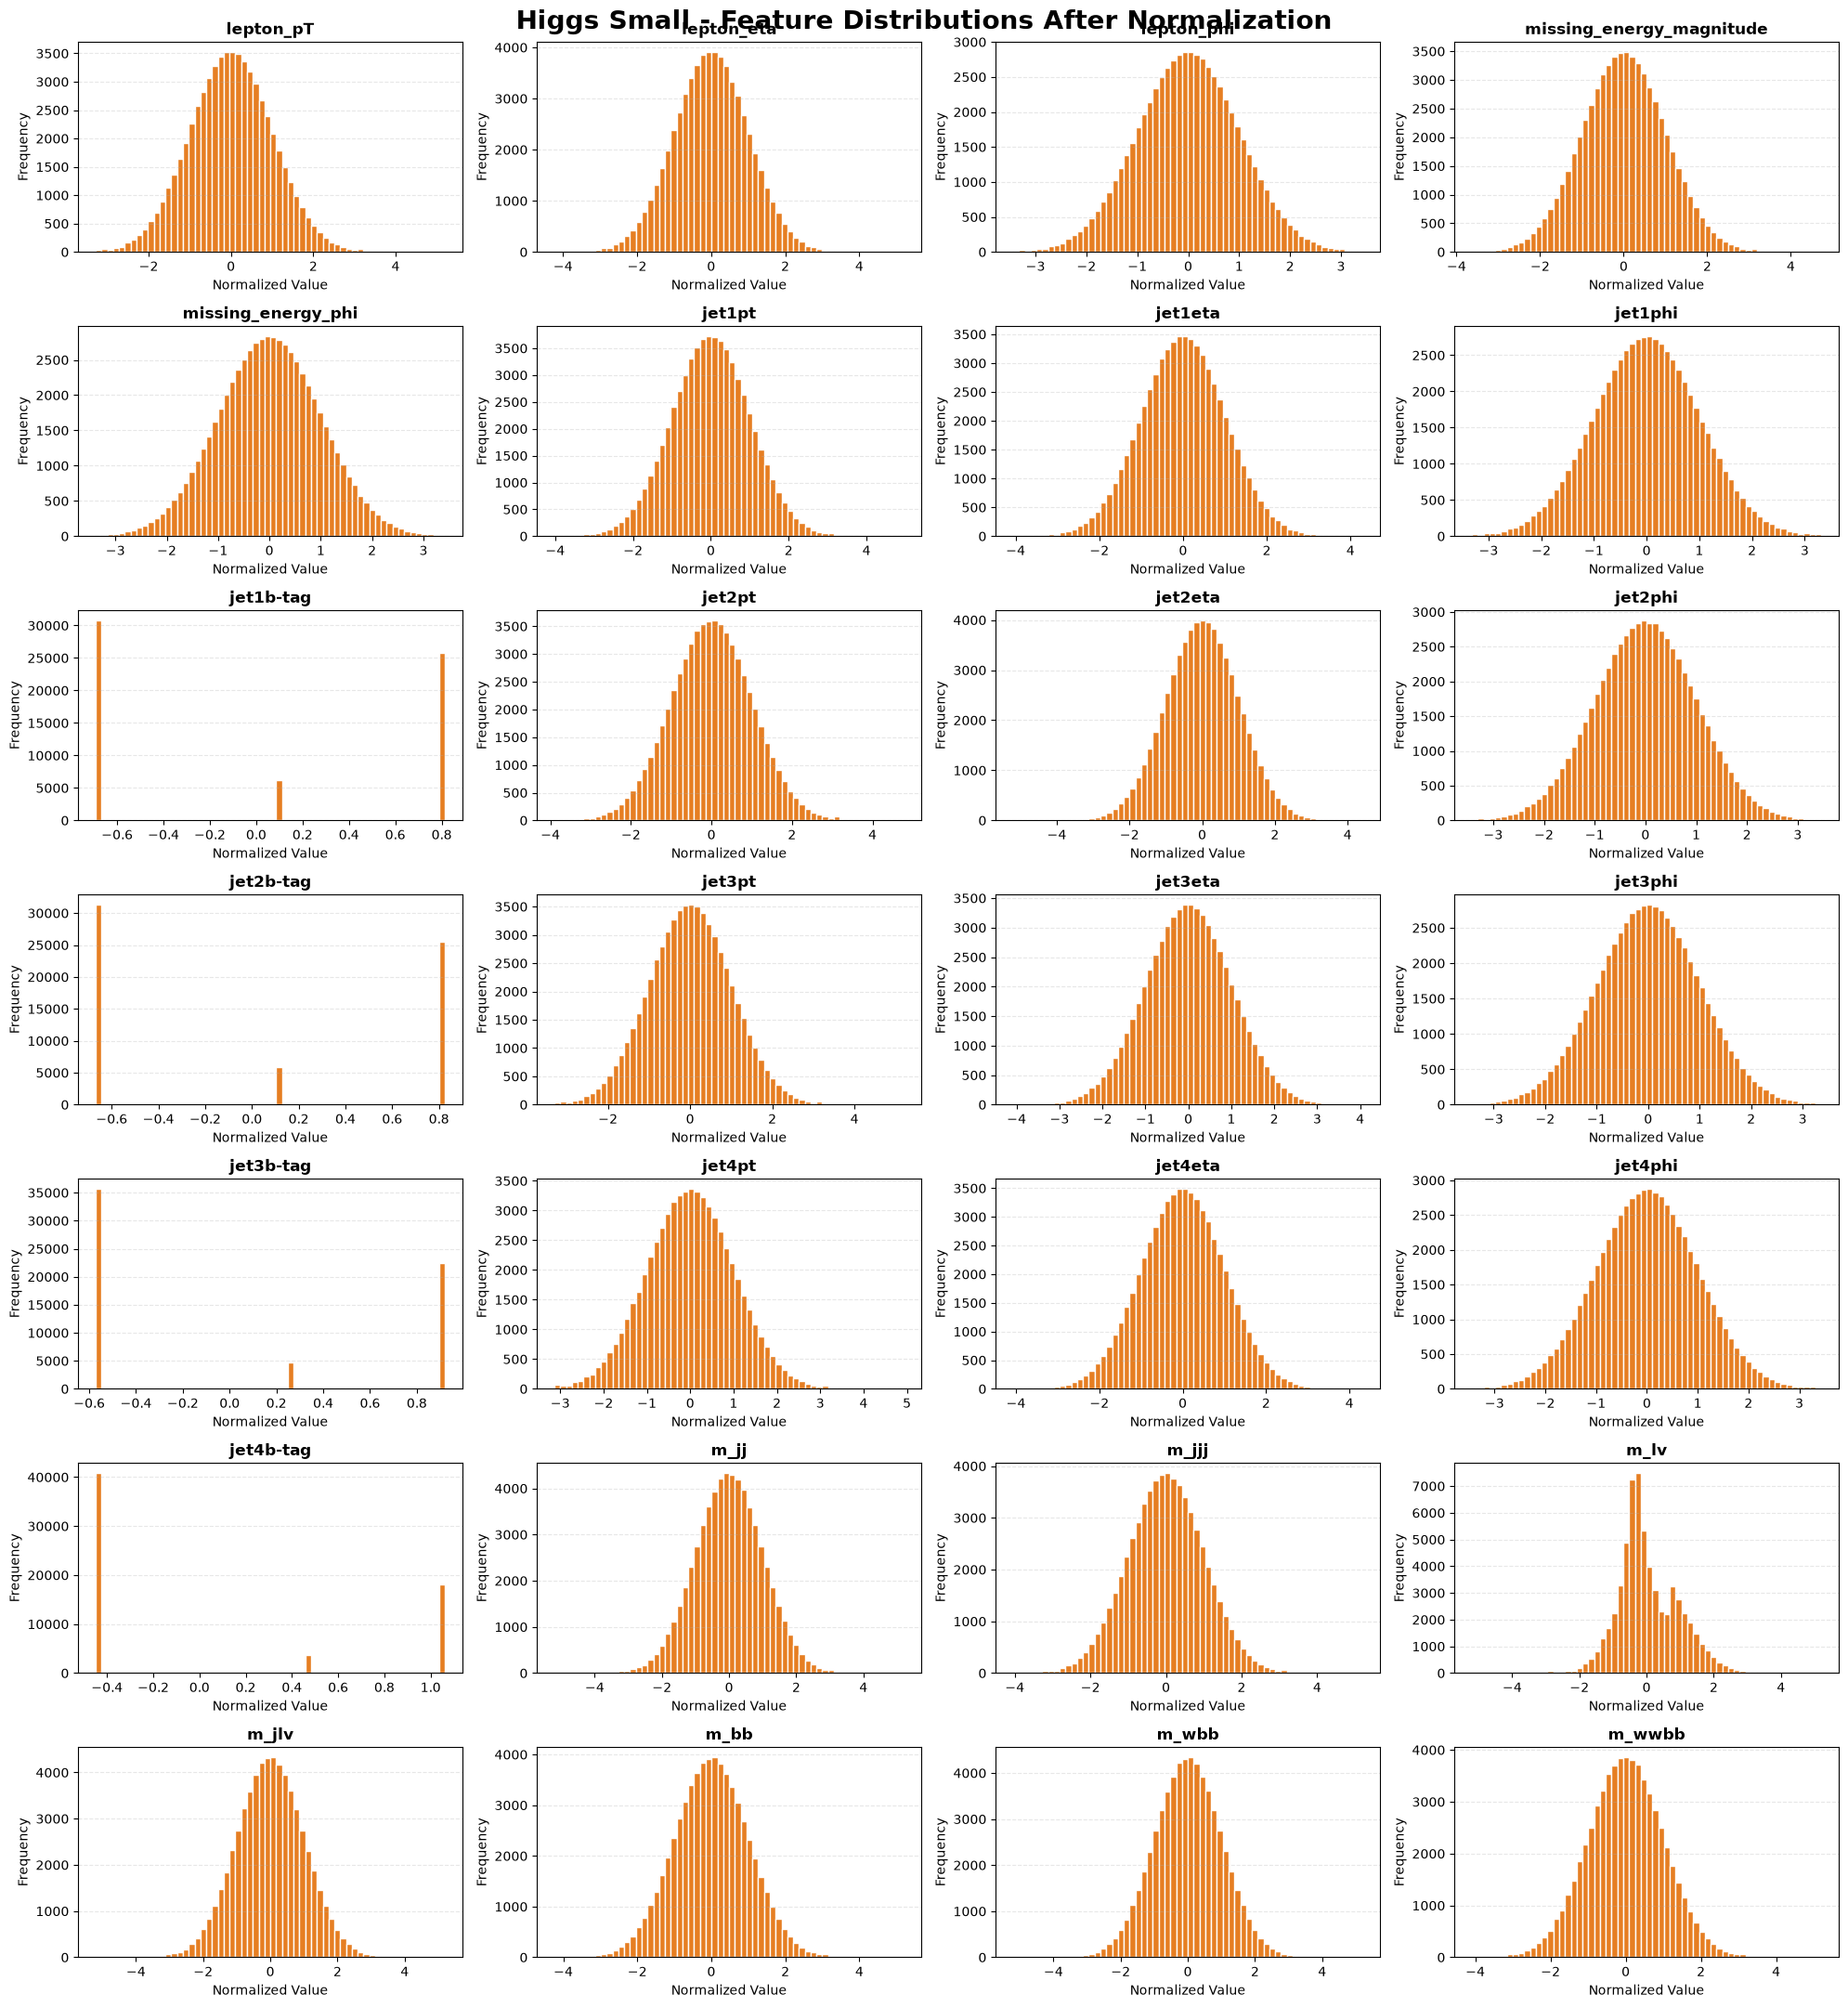

In [15]:
fig, axes = plt.subplots(7, 4, figsize=(20, 22))

axes = axes.flatten()

for i, feature in enumerate(FEATURE_NAMES):

    axes[i].hist(
        X_train_norm[:, i],
        bins=60,
        color="#e67e22",
        edgecolor="white"
    )

    axes[i].set_title(feature, fontweight="bold")
    axes[i].set_xlabel("Normalized Value")
    axes[i].set_ylabel("Frequency")
    axes[i].grid(axis="y", linestyle="--", alpha=0.3)

fig.suptitle(
    "Higgs Small - Feature Distributions After Normalization",
    fontsize=20,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [16]:
# Convert normalized training data to DataFrame
X_train_norm_df = pd.DataFrame(
    X_train_norm,
    columns=FEATURE_NAMES,
    index=X_train.index
)

# Statistical comparison
NORMALIZATION_SUMMARY = pd.DataFrame({

    "Mean Before": X_train.mean(),
    "Mean After": X_train_norm_df.mean(),

    "Std Before": X_train.std(),
    "Std After": X_train_norm_df.std(),

    "Skewness Before": X_train.skew(),
    "Skewness After": X_train_norm_df.skew(),

    "Min Before": X_train.min(),
    "Min After": X_train_norm_df.min(),

    "Max Before": X_train.max(),
    "Max After": X_train_norm_df.max()
})

display(NORMALIZATION_SUMMARY.round(8))

,Mean Before,Mean After,Std Before,Std After,Skewness Before,Skewness After,Min Before,Min After,Max Before,Max After
lepton_pT,0.992984,0.000005,0.566382,0.998640,1.765551,0.000571,0.274697,-3.286182,7.805887,5.199337
lepton_eta,-0.006012,0.000046,1.002985,0.999689,0.006575,0.001599,-2.434976,-4.232299,2.431946,5.199337
lepton_phi,-0.005454,-0.000023,1.004857,0.999016,0.001259,-0.000576,-1.742508,-3.438242,1.743236,3.422969
missing_energy_magnitude,0.993414,-0.000054,0.593927,0.999001,1.453589,-0.001154,0.007146,-3.632023,7.074050,4.728219
missing_energy_phi,-0.008949,0.000011,1.006233,0.999171,0.007291,0.000661,-1.743927,-3.384328,1.743213,3.419899
jet1pt,0.987127,-0.000021,0.473217,0.998669,1.951303,-0.000636,0.139976,-4.020292,7.064657,4.957175
jet1eta,-0.003678,0.000001,1.007066,0.999314,-0.011252,0.000584,-2.968735,-4.058871,2.969674,4.286882
jet1phi,0.001084,-0.000030,1.010365,0.998944,-0.002285,-0.000661,-1.741237,-3.315434,1.741454,3.313751
jet1b-tag,0.998683,0.004057,1.027305,0.712867,0.161523,0.143849,0.000000,-0.692674,2.173076,0.814276
jet2pt,0.991264,-0.000126,0.500237,0.999021,2.055667,-0.003124,0.188981,-3.899884,8.280169,4.776003


## PyTorch Data Preparation

In [17]:
# Convert features to tensors
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


X_TENSOR = {
    "train": torch.as_tensor(
        X_train_norm, dtype=torch.float32, device=DEVICE
    ),
    "val": torch.as_tensor(
        X_val_norm, dtype=torch.float32, device=DEVICE
    ),
    "test": torch.as_tensor(
        X_test_norm, dtype=torch.float32, device=DEVICE
    )
}

In [18]:
# Convert targets to tensors
Y_TENSOR = {
    "train": torch.as_tensor(
        y_train.to_numpy(dtype=np.float32), dtype=torch.float32, device=DEVICE
    ),
    "val": torch.as_tensor(
        y_val.to_numpy(dtype=np.float32), dtype=torch.float32, device=DEVICE
    ),
    "test": torch.as_tensor(
        y_test.to_numpy(dtype=np.float32), dtype=torch.float32, device=DEVICE
    )
}

In [19]:
import math

BATCH_SIZE = 512
EVAL_BATCH_SIZE = 8192

TRAIN_SIZE = len(X_TENSOR["train"])

STEPS_PER_EPOCH = math.ceil(
    TRAIN_SIZE / BATCH_SIZE
)

print("Training Samples:", TRAIN_SIZE)
print("Batch Size:", BATCH_SIZE)
print("Evaluation Batch Size:", EVAL_BATCH_SIZE)
print("Steps Per Epoch:", STEPS_PER_EPOCH)

Training Samples: 62752
Batch Size: 512
Evaluation Batch Size: 8192
Steps Per Epoch: 123


## Original FT-Transformer Architecture


In [20]:
import random
import typing as ty

import torch.nn as nn
import torch.nn.functional as F
import torch.nn.init as nn_init
from torch import Tensor

In [21]:
class Tokenizer(nn.Module):
    category_offsets: ty.Optional[Tensor]

    def __init__(self, d_numerical: int, categories: ty.Optional[ty.List[int]],
                 d_token: int, bias: bool) -> None:
        super().__init__()
        if categories is None:
            d_bias = d_numerical
            self.category_offsets = None
            self.category_embeddings = None
        else:
            d_bias = d_numerical + len(categories)
            category_offsets = torch.tensor([0] + categories[:-1]).cumsum(0)
            self.register_buffer('category_offsets', category_offsets)
            self.category_embeddings = nn.Embedding(sum(categories), d_token)
            nn_init.kaiming_uniform_(self.category_embeddings.weight, a=math.sqrt(5))
            print(f'{self.category_embeddings.weight.shape=}')

        # Include the CLS token in the weight matrix.
        self.weight = nn.Parameter(Tensor(d_numerical + 1, d_token))
        self.bias = nn.Parameter(Tensor(d_bias, d_token)) if bias else None
        nn_init.kaiming_uniform_(self.weight, a=math.sqrt(5))
        if self.bias is not None:
            nn_init.kaiming_uniform_(self.bias, a=math.sqrt(5))

    @property
    def n_tokens(self) -> int:
        return len(self.weight) + (
            0 if self.category_offsets is None else len(self.category_offsets)
        )

    def forward(self, x_num: Tensor, x_cat: ty.Optional[Tensor]) -> Tensor:
        x_some = x_num if x_cat is None else x_cat
        assert x_some is not None
        x_num = torch.cat(
            [torch.ones(len(x_some), 1, device=x_some.device)]
            + ([] if x_num is None else [x_num]), dim=1
        )
        x = self.weight[None] * x_num[:, :, None]
        if x_cat is not None:
            x = torch.cat(
                [x, self.category_embeddings(x_cat + self.category_offsets[None])], dim=1
            )
        if self.bias is not None:
            bias = torch.cat([
                torch.zeros(1, self.bias.shape[1], device=x.device), self.bias
            ])
            x = x + bias[None]
        return x

### Activation Functions

In [22]:
def reglu(x: Tensor) -> Tensor:
    a, b = x.chunk(2, dim=-1)
    return a * F.relu(b)


def geglu(x: Tensor) -> Tensor:
    a, b = x.chunk(2, dim=-1)
    return a * F.gelu(b)


def get_activation_fn(name: str) -> ty.Callable[[Tensor], Tensor]:
    return (
        reglu if name == 'reglu' else
        geglu if name == 'geglu' else
        torch.sigmoid if name == 'sigmoid' else
        getattr(F, name)
    )


def get_nonglu_activation_fn(name: str) -> ty.Callable[[Tensor], Tensor]:
    return (
        F.relu if name == 'reglu' else
        F.gelu if name == 'geglu' else
        get_activation_fn(name)
    )

### Multi-Head Self-Attention

In [23]:
class MultiheadAttention(nn.Module):
    def __init__(self, d: int, n_heads: int, dropout: float,
                 initialization: str) -> None:
        if n_heads > 1:
            assert d % n_heads == 0
        assert initialization in ['xavier', 'kaiming']
        super().__init__()
        self.W_q = nn.Linear(d, d)
        self.W_k = nn.Linear(d, d)
        self.W_v = nn.Linear(d, d)
        self.W_out = nn.Linear(d, d) if n_heads > 1 else None
        self.n_heads = n_heads
        self.dropout = nn.Dropout(dropout) if dropout else None
        for m in [self.W_q, self.W_k, self.W_v]:
            if initialization == 'xavier' and (n_heads > 1 or m is not self.W_v):
                nn_init.xavier_uniform_(m.weight, gain=1 / math.sqrt(2))
            nn_init.zeros_(m.bias)
        if self.W_out is not None:
            nn_init.zeros_(self.W_out.bias)

    def _reshape(self, x: Tensor) -> Tensor:
        batch_size, n_tokens, d = x.shape
        d_head = d // self.n_heads
        return (
            x.reshape(batch_size, n_tokens, self.n_heads, d_head)
            .transpose(1, 2)
            .reshape(batch_size * self.n_heads, n_tokens, d_head)
        )

    def forward(self, x_q: Tensor, x_kv: Tensor,
                key_compression: ty.Optional[nn.Linear],
                value_compression: ty.Optional[nn.Linear]) -> Tensor:
        q, k, v = self.W_q(x_q), self.W_k(x_kv), self.W_v(x_kv)
        for tensor in [q, k, v]:
            assert tensor.shape[-1] % self.n_heads == 0
        if key_compression is not None:
            assert value_compression is not None
            k = key_compression(k.transpose(1, 2)).transpose(1, 2)
            v = value_compression(v.transpose(1, 2)).transpose(1, 2)
        else:
            assert value_compression is None
        batch_size = len(q)
        d_head_key = k.shape[-1] // self.n_heads
        d_head_value = v.shape[-1] // self.n_heads
        n_q_tokens = q.shape[1]
        q = self._reshape(q)
        k = self._reshape(k)
        attention = F.softmax(q @ k.transpose(1, 2) / math.sqrt(d_head_key), dim=-1)
        if self.dropout is not None:
            attention = self.dropout(attention)
        x = attention @ self._reshape(v)
        x = (
            x.reshape(batch_size, self.n_heads, n_q_tokens, d_head_value)
            .transpose(1, 2)
            .reshape(batch_size, n_q_tokens, self.n_heads * d_head_value)
        )
        if self.W_out is not None:
            x = self.W_out(x)
        return x

### Transformer

In [24]:
class Transformer(nn.Module):
    def __init__(self, *, d_numerical: int,
                 categories: ty.Optional[ty.List[int]], token_bias: bool,
                 n_layers: int, d_token: int, n_heads: int,
                 d_ffn_factor: float, attention_dropout: float,
                 ffn_dropout: float, residual_dropout: float,
                 activation: str, prenormalization: bool, initialization: str,
                 kv_compression: ty.Optional[float],
                 kv_compression_sharing: ty.Optional[str], d_out: int) -> None:
        assert (kv_compression is None) ^ (kv_compression_sharing is not None)
        super().__init__()
        self.tokenizer = Tokenizer(d_numerical, categories, d_token, token_bias)
        n_tokens = self.tokenizer.n_tokens

        def make_kv_compression():
            assert kv_compression
            compression = nn.Linear(n_tokens, int(n_tokens * kv_compression), bias=False)
            if initialization == 'xavier':
                nn_init.xavier_uniform_(compression.weight)
            return compression

        self.shared_kv_compression = (
            make_kv_compression()
            if kv_compression and kv_compression_sharing == 'layerwise' else None
        )

        def make_normalization():
            return nn.LayerNorm(d_token)

        d_hidden = int(d_token * d_ffn_factor)
        self.layers = nn.ModuleList([])
        for layer_idx in range(n_layers):
            layer = nn.ModuleDict({
                'attention': MultiheadAttention(d_token, n_heads, attention_dropout, initialization),
                'linear0': nn.Linear(d_token, d_hidden * (2 if activation.endswith('glu') else 1)),
                'linear1': nn.Linear(d_hidden, d_token),
                'norm1': make_normalization(),
            })
            if not prenormalization or layer_idx:
                layer['norm0'] = make_normalization()
            if kv_compression and self.shared_kv_compression is None:
                layer['key_compression'] = make_kv_compression()
                if kv_compression_sharing == 'headwise':
                    layer['value_compression'] = make_kv_compression()
                else:
                    assert kv_compression_sharing == 'key-value'
            self.layers.append(layer)

        self.activation = get_activation_fn(activation)
        self.last_activation = get_nonglu_activation_fn(activation)
        self.prenormalization = prenormalization
        self.last_normalization = make_normalization() if prenormalization else None
        self.ffn_dropout = ffn_dropout
        self.residual_dropout = residual_dropout
        self.head = nn.Linear(d_token, d_out)

    def _get_kv_compressions(self, layer):
        return (
            (self.shared_kv_compression, self.shared_kv_compression)
            if self.shared_kv_compression is not None
            else (layer['key_compression'], layer['value_compression'])
            if 'key_compression' in layer and 'value_compression' in layer
            else (layer['key_compression'], layer['key_compression'])
            if 'key_compression' in layer
            else (None, None)
        )

    def _start_residual(self, x, layer, norm_idx):
        x_residual = x
        if self.prenormalization:
            norm_key = f'norm{norm_idx}'
            if norm_key in layer:
                x_residual = layer[norm_key](x_residual)
        return x_residual

    def _end_residual(self, x, x_residual, layer, norm_idx):
        if self.residual_dropout:
            x_residual = F.dropout(x_residual, self.residual_dropout, self.training)
        x = x + x_residual
        if not self.prenormalization:
            x = layer[f'norm{norm_idx}'](x)
        return x

    def forward(self, x_num: Tensor, x_cat: ty.Optional[Tensor]) -> Tensor:
        x = self.tokenizer(x_num, x_cat)
        for layer_idx, layer in enumerate(self.layers):
            is_last_layer = layer_idx + 1 == len(self.layers)
            layer = ty.cast(ty.Dict[str, nn.Module], layer)
            x_residual = self._start_residual(x, layer, 0)
            x_residual = layer['attention'](
                x_residual[:, :1] if is_last_layer else x_residual,
                x_residual, *self._get_kv_compressions(layer)
            )
            if is_last_layer:
                x = x[:, :x_residual.shape[1]]
            x = self._end_residual(x, x_residual, layer, 0)
            x_residual = self._start_residual(x, layer, 1)
            x_residual = layer['linear0'](x_residual)
            x_residual = self.activation(x_residual)
            if self.ffn_dropout:
                x_residual = F.dropout(x_residual, self.ffn_dropout, self.training)
            x_residual = layer['linear1'](x_residual)
            x = self._end_residual(x, x_residual, layer, 1)
        assert x.shape[1] == 1
        x = x[:, 0]
        if self.last_normalization is not None:
            x = self.last_normalization(x)
        x = self.last_activation(x)
        x = self.head(x)
        return x.squeeze(-1)

In [25]:
MODEL_CONFIG = {
    'activation': 'reglu',
    'attention_dropout': 0.2285776112227358,
    'd_ffn_factor': 2.44721762662163,
    'd_token': 264,
    'ffn_dropout': 0.3224216086083693,
    'initialization': 'kaiming',
    'n_heads': 8,
    'n_layers': 2,
    'prenormalization': True,
    'residual_dropout': 0.0,
    'token_bias': True,
    'kv_compression': None,
    'kv_compression_sharing': None,
}
MODEL_SEED = 0

In [26]:
random.seed(MODEL_SEED)
np.random.seed(MODEL_SEED)
torch.manual_seed(MODEL_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(MODEL_SEED)
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False

MODEL = Transformer(
    d_numerical=28,
    categories=None,
    d_out=1,
    **MODEL_CONFIG
).to(DEVICE)
print(MODEL)

Transformer(
  (tokenizer): Tokenizer()
  (layers): ModuleList(
    (0): ModuleDict(
      (attention): MultiheadAttention(
        (W_q): Linear(in_features=264, out_features=264, bias=True)
        (W_k): Linear(in_features=264, out_features=264, bias=True)
        (W_v): Linear(in_features=264, out_features=264, bias=True)
        (W_out): Linear(in_features=264, out_features=264, bias=True)
        (dropout): Dropout(p=0.2285776112227358, inplace=False)
      )
      (linear0): Linear(in_features=264, out_features=1292, bias=True)
      (linear1): Linear(in_features=646, out_features=264, bias=True)
      (norm1): LayerNorm((264,), eps=1e-05, elementwise_affine=True, bias=True)
    )
    (1): ModuleDict(
      (attention): MultiheadAttention(
        (W_q): Linear(in_features=264, out_features=264, bias=True)
        (W_k): Linear(in_features=264, out_features=264, bias=True)
        (W_v): Linear(in_features=264, out_features=264, bias=True)
        (W_out): Linear(in_features=264

In [27]:
TOTAL_PARAMETERS = sum(p.numel() for p in MODEL.parameters())
TRAINABLE_PARAMETERS = sum(p.numel() for p in MODEL.parameters() if p.requires_grad)
PUBLISHED_PARAMETERS = 1_603_481

print(f"Total parameters:     {TOTAL_PARAMETERS:,}")
print(f"Trainable parameters: {TRAINABLE_PARAMETERS:,}")
print(f"Published parameters: {PUBLISHED_PARAMETERS:,}")
assert TRAINABLE_PARAMETERS == PUBLISHED_PARAMETERS
print("Parameter count verification: Passed")

Total parameters:     1,603,481
Trainable parameters: 1,603,481
Published parameters: 1,603,481
Parameter count verification: Passed


### Forward Pass Verification

In [28]:
MODEL.eval()
if "X_TENSOR" in globals() and "Y_TENSOR" in globals():
    SAMPLE_X = X_TENSOR["train"][:globals().get("BATCH_SIZE", 512)]
    SAMPLE_Y = Y_TENSOR["train"][:len(SAMPLE_X)]
    print("Using real training data")
else:
    SAMPLE_X = torch.zeros(8, 28, device=DEVICE)
    SAMPLE_Y = torch.zeros(8, device=DEVICE)
    print("Using synthetic data for the standalone smoke test")

with torch.no_grad():
    SAMPLE_TOKENS = MODEL.tokenizer(SAMPLE_X, None)
    LOGITS = MODEL(SAMPLE_X, None)
    PROBABILITIES = torch.sigmoid(LOGITS)

print("Input shape:", tuple(SAMPLE_X.shape))
print("Token shape:", tuple(SAMPLE_TOKENS.shape))
print("Logits shape:", tuple(LOGITS.shape))
assert SAMPLE_TOKENS.shape == (len(SAMPLE_X), 29, 264)
assert LOGITS.shape == SAMPLE_Y.shape
assert torch.isfinite(LOGITS).all()
print("Forward pass verification: Passed")
MODEL.train()

Using real training data
Input shape: (512, 28)
Token shape: (512, 29, 264)
Logits shape: (512,)
Forward pass verification: Passed


Transformer(
  (tokenizer): Tokenizer()
  (layers): ModuleList(
    (0): ModuleDict(
      (attention): MultiheadAttention(
        (W_q): Linear(in_features=264, out_features=264, bias=True)
        (W_k): Linear(in_features=264, out_features=264, bias=True)
        (W_v): Linear(in_features=264, out_features=264, bias=True)
        (W_out): Linear(in_features=264, out_features=264, bias=True)
        (dropout): Dropout(p=0.2285776112227358, inplace=False)
      )
      (linear0): Linear(in_features=264, out_features=1292, bias=True)
      (linear1): Linear(in_features=646, out_features=264, bias=True)
      (norm1): LayerNorm((264,), eps=1e-05, elementwise_affine=True, bias=True)
    )
    (1): ModuleDict(
      (attention): MultiheadAttention(
        (W_q): Linear(in_features=264, out_features=264, bias=True)
        (W_k): Linear(in_features=264, out_features=264, bias=True)
        (W_v): Linear(in_features=264, out_features=264, bias=True)
        (W_out): Linear(in_features=264

## Training Configuration

In [29]:
TRAINING_CONFIG = {
    "optimizer": "adamw",
    "lr": 2.520396383745548e-05,
    "weight_decay": 1.871343748594096e-05,
    "batch_size": 512,
    "eval_batch_size": 8192,
    "n_epochs": 1000000000,
    "patience": 16
}

LEARNING_RATE = TRAINING_CONFIG["lr"]
WEIGHT_DECAY = TRAINING_CONFIG["weight_decay"]

BATCH_SIZE = TRAINING_CONFIG["batch_size"]
EVAL_BATCH_SIZE = TRAINING_CONFIG["eval_batch_size"]

MAX_EPOCHS = TRAINING_CONFIG["n_epochs"]
PATIENCE = TRAINING_CONFIG["patience"]

display(pd.DataFrame(
    TRAINING_CONFIG.items(),
    columns=["Hyperparameter", "Value"]
))

,Hyperparameter,Value
0,optimizer,adamw
1,lr,0.000025
2,weight_decay,0.000019
3,batch_size,512
4,eval_batch_size,8192
5,n_epochs,1000000000
6,patience,16


## Weight Decay Parameter Groups

In [30]:
def needs_weight_decay(name):

    return all(
        keyword not in name
        for keyword in ["tokenizer", ".norm", ".bias"]
    )


PARAMETERS_WITH_WD = [
    param
    for name, param in MODEL.named_parameters()
    if needs_weight_decay(name)
]

PARAMETERS_WITHOUT_WD = [
    param
    for name, param in MODEL.named_parameters()
    if not needs_weight_decay(name)
]


PARAMETER_GROUPS = [
    {
        "params": PARAMETERS_WITH_WD
    },
    {
        "params": PARAMETERS_WITHOUT_WD,
        "weight_decay": 0.0
    }
]

print("Parameter groups created successfully.")

Parameter groups created successfully.


In [31]:
N_PARAMS_WITH_WD = sum(
    p.numel()
    for p in PARAMETERS_WITH_WD
)

N_PARAMS_WITHOUT_WD = sum(
    p.numel()
    for p in PARAMETERS_WITHOUT_WD
)

TOTAL_GROUPED_PARAMS = (
    N_PARAMS_WITH_WD + N_PARAMS_WITHOUT_WD
)

PARAMETER_GROUP_SUMMARY = pd.DataFrame({
    "Parameter Group": [
        "With Weight Decay",
        "Without Weight Decay",
        "Total"
    ],
    "Parameters": [
        N_PARAMS_WITH_WD,
        N_PARAMS_WITHOUT_WD,
        TOTAL_GROUPED_PARAMS
    ],
    "Weight Decay": [
        WEIGHT_DECAY,
        0.0,
        "-"
    ]
})

display(PARAMETER_GROUP_SUMMARY)

assert TOTAL_GROUPED_PARAMS == sum(
    p.numel() for p in MODEL.parameters()
)

assert not (
    {id(p) for p in PARAMETERS_WITH_WD}
    &
    {id(p) for p in PARAMETERS_WITHOUT_WD}
)

print("Parameter Groups Verification: Passed")

,Parameter Group,Parameters,Weight Decay
0,With Weight Decay,1581360,0.000019
1,Without Weight Decay,22121,0.0
2,Total,1603481,-


Parameter Groups Verification: Passed


In [32]:
OPTIMIZER = torch.optim.AdamW(
    PARAMETER_GROUPS,
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

print(OPTIMIZER)

AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 2.520396383745548e-05
    maximize: False
    weight_decay: 1.871343748594096e-05

Parameter Group 1
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 2.520396383745548e-05
    maximize: False
    weight_decay: 0.0
)


### Index-Based Batch Loading

In [33]:
class IndexLoader:

    def __init__(
        self,
        train_size,
        batch_size,
        shuffle,
        device
    ):

        self.train_size = train_size
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.device = device

    def __len__(self):

        return math.ceil(
            self.train_size / self.batch_size
        )

    def __iter__(self):

        if self.shuffle:

            indices = torch.randperm(
                self.train_size
            )

        else:

            indices = torch.arange(
                self.train_size
            )

        indices = indices.to(self.device)

        return iter(indices.split(self.batch_size))

In [34]:
TRAIN_LOADER = IndexLoader(
    train_size=len(X_TENSOR["train"]),
    batch_size=BATCH_SIZE,
    shuffle=True,
    device=DEVICE
)

VAL_LOADER = IndexLoader(
    train_size=len(X_TENSOR["val"]),
    batch_size=EVAL_BATCH_SIZE,
    shuffle=False,
    device=DEVICE
)

TEST_LOADER = IndexLoader(
    train_size=len(X_TENSOR["test"]),
    batch_size=EVAL_BATCH_SIZE,
    shuffle=False,
    device=DEVICE
)

LOADER_SUMMARY = pd.DataFrame([
    {
        "Dataset": "Train",
        "Samples": len(X_TENSOR["train"]),
        "Batch Size": BATCH_SIZE,
        "Batches": len(TRAIN_LOADER),
        "Shuffle": True
    },
    {
        "Dataset": "Validation",
        "Samples": len(X_TENSOR["val"]),
        "Batch Size": EVAL_BATCH_SIZE,
        "Batches": len(VAL_LOADER),
        "Shuffle": False
    },
    {
        "Dataset": "Test",
        "Samples": len(X_TENSOR["test"]),
        "Batch Size": EVAL_BATCH_SIZE,
        "Batches": len(TEST_LOADER),
        "Shuffle": False
    }
])

display(LOADER_SUMMARY)

,Dataset,Samples,Batch Size,Batches,Shuffle
0,Train,62752,512,123,True
1,Validation,15688,8192,2,False
2,Test,19610,8192,3,False


### LOSS FUNCTION

In [35]:
LOSS_FN = F.binary_cross_entropy_with_logits

print("Loss Function:", LOSS_FN.__name__)

Loss Function: binary_cross_entropy_with_logits


In [36]:
MODEL.eval()

SAMPLE_X = X_TENSOR["train"][:BATCH_SIZE]
SAMPLE_Y = Y_TENSOR["train"][:BATCH_SIZE]

with torch.no_grad():

    SAMPLE_LOGITS = MODEL(SAMPLE_X, None)

    SAMPLE_LOSS = LOSS_FN(
        SAMPLE_LOGITS,
        SAMPLE_Y
    )

print("Logits Shape:", SAMPLE_LOGITS.shape)
print("Target Shape:", SAMPLE_Y.shape)
print("Initial Loss:", SAMPLE_LOSS.item())

assert SAMPLE_LOGITS.shape == SAMPLE_Y.shape
assert torch.isfinite(SAMPLE_LOSS)

MODEL.train()

print("\nLoss Function Verification: Passed")

Logits Shape: torch.Size([512])
Target Shape: torch.Size([512])
Initial Loss: 0.7261008024215698

Loss Function Verification: Passed


## Model Training

In [37]:
from scipy.special import expit
from sklearn.metrics import accuracy_score, roc_auc_score

OUTPUT_DIR = Path(
    "../outputs/higgs_small/ft_transformer/baseline/seed_0"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CHECKPOINT_PATH = OUTPUT_DIR / "checkpoint.pt"
HISTORY_PATH = OUTPUT_DIR / "training_history.csv"

print("Output Directory:", OUTPUT_DIR.resolve())
print("History Path    :", HISTORY_PATH)
print("Checkpoint Path :", CHECKPOINT_PATH)

Output Directory: /home/racoon/Downloads/Deep-Tabular-project/outputs/higgs_small/ft_transformer/baseline/seed_0
History Path    : ../outputs/higgs_small/ft_transformer/baseline/seed_0/training_history.csv
Checkpoint Path : ../outputs/higgs_small/ft_transformer/baseline/seed_0/checkpoint.pt


In [38]:
@torch.no_grad()
def evaluate(part):

    MODEL.eval()

    loader = IndexLoader(
        train_size=len(X_TENSOR[part]),
        batch_size=EVAL_BATCH_SIZE,
        shuffle=False,
        device=DEVICE
    )

    all_logits = []

    for batch_idx in loader:

        batch_logits = MODEL(
            X_TENSOR[part][batch_idx],
            None
        )

        all_logits.append(batch_logits.cpu())

    logits = torch.cat(all_logits)

    targets = Y_TENSOR[part].cpu()

    # Calculate evaluation loss
    loss = LOSS_FN(logits, targets).item()

    # Convert logits to probabilities
    probabilities = expit(logits.numpy())

    # Original repository prediction strategy
    predictions = np.round(
        probabilities
    ).astype(np.int64)

    y_true = targets.numpy()

    metrics = {
        "loss": loss,
        "accuracy": accuracy_score(
            y_true, predictions
        ),
        "roc_auc": roc_auc_score(
            y_true, probabilities
        )
    }

    return metrics

In [39]:
INITIAL_VAL_METRICS = evaluate("val")

display(
    pd.DataFrame(
        INITIAL_VAL_METRICS,
        index=["Before Training"]
    )
)

,loss,accuracy,roc_auc
Before Training,0.735381,0.528557,0.532124


In [40]:
def train_one_epoch():

    MODEL.train()

    epoch_losses = []

    for batch_idx in TRAIN_LOADER:

        # Select batch
        batch_x = X_TENSOR["train"][batch_idx]
        batch_y = Y_TENSOR["train"][batch_idx]

        # Reset gradients
        OPTIMIZER.zero_grad()

        # Forward pass
        logits = MODEL(batch_x, None)

        # Calculate loss
        loss = LOSS_FN(logits, batch_y)

        # Backward pass
        loss.backward()

        # Update parameters
        OPTIMIZER.step()

        # Store batch loss
        epoch_losses.append(loss.detach())

    # Mean batch loss
    epoch_loss = torch.stack(
        epoch_losses
    ).mean().item()

    return epoch_loss

In [41]:
class EarlyStopping:

    def __init__(self, patience=16):

        self.patience = patience

        self.best_score = -float("inf")
        self.best_epoch = 0

        self.counter = 0
        self.early_stop = False

    def update(self, score, epoch):

        improved = score > self.best_score

        if improved:

            self.best_score = score
            self.best_epoch = epoch

            self.counter = 0

        else:

            self.counter += 1

            if self.counter > self.patience:

                self.early_stop = True

        return improved

In [42]:
def save_checkpoint(epoch, val_metrics):

    checkpoint = {

        "epoch": epoch,

        "model_state_dict": MODEL.state_dict(),

        "optimizer_state_dict": OPTIMIZER.state_dict(),

        "validation_metrics": val_metrics,

        "model_config": MODEL_CONFIG,

        "training_config": TRAINING_CONFIG,

        "seed": SEED
    }

    torch.save(
        checkpoint,
        CHECKPOINT_PATH
    )

In [43]:
EARLY_STOPPING = EarlyStopping(
    patience=PATIENCE
)

HISTORY = {
    "epoch": [],
    "train_loss": [],
    "val_loss": [],
    "val_accuracy": [],
    "val_roc_auc": [],
    "test_accuracy": [],
    "test_roc_auc": [],
    "epoch_time": []
}

# Match the original repository evaluation schedule
LOG_TEST_EACH_EPOCH = True

print("Maximum Epochs:", MAX_EPOCHS)
print("Patience:", PATIENCE)
print("Batch Size:", BATCH_SIZE)
print("Learning Rate:", LEARNING_RATE)
print("Weight Decay:", WEIGHT_DECAY)

Maximum Epochs: 1000000000
Patience: 16
Batch Size: 512
Learning Rate: 2.520396383745548e-05
Weight Decay: 1.871343748594096e-05


## Main Training Loop

In [44]:
from datetime import timedelta

print("=" * 80)
print("Original FT-Transformer Training")
print("Dataset: Higgs Small")
print("=" * 80)

if DEVICE.type == "cuda":
    torch.cuda.synchronize()

TRAINING_START_TIME = time.perf_counter()

for epoch in range(1, MAX_EPOCHS + 1):

    EPOCH_START_TIME = time.perf_counter()

    # Training
    train_loss = train_one_epoch()

    # Validation
    val_metrics = evaluate("val")

    val_loss = val_metrics["loss"]
    val_accuracy = val_metrics["accuracy"]
    val_roc_auc = val_metrics["roc_auc"]

    # Test Logging

    if LOG_TEST_EACH_EPOCH:

        test_metrics = evaluate("test")

        test_accuracy = test_metrics["accuracy"]
        test_roc_auc = test_metrics["roc_auc"]

    else:

        test_accuracy = np.nan
        test_roc_auc = np.nan

    # Early Stopping & Checkpoint

    improved = EARLY_STOPPING.update(
        score=val_accuracy,
        epoch=epoch
    )

    if improved:

        save_checkpoint(
            epoch,
            val_metrics
        )

    # Calculate Epoch Time

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

    epoch_time = (
        time.perf_counter() - EPOCH_START_TIME
    )

    # Store Training History

    HISTORY["epoch"].append(epoch)

    HISTORY["train_loss"].append(train_loss)
    HISTORY["val_loss"].append(val_loss)

    HISTORY["val_accuracy"].append(val_accuracy)
    HISTORY["val_roc_auc"].append(val_roc_auc)

    HISTORY["test_accuracy"].append(test_accuracy)
    HISTORY["test_roc_auc"].append(test_roc_auc)

    HISTORY["epoch_time"].append(epoch_time)

    # Save history after each epoch
    pd.DataFrame(HISTORY).to_csv(
        HISTORY_PATH,
        index=False
    )

    # Display Epoch Results

    status = (
        "BEST MODEL"
        if improved
        else f"Patience: {EARLY_STOPPING.counter}/{PATIENCE}"
    )

    print(
        f"Epoch {epoch:03d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f} | "
        f"Val AUC: {val_roc_auc:.4f} | "
        f"Time: {epoch_time:.2f}s | "
        f"{status}"
    )

    # Stop Training

    if EARLY_STOPPING.early_stop:

        print("\nEarly Stopping Triggered!")

        break


if DEVICE.type == "cuda":
    torch.cuda.synchronize()

TOTAL_TRAINING_TIME = (
    time.perf_counter() - TRAINING_START_TIME
)

print("\n" + "=" * 80)
print("Training Completed")
print("=" * 80)

print("Total Epochs:", len(HISTORY["epoch"]))

print("Best Epoch:", EARLY_STOPPING.best_epoch)

print(
    f"Best Validation Accuracy: "
    f"{EARLY_STOPPING.best_score * 100:.4f}%"
)

print(
    f"Total Training Time: "
    f"{TOTAL_TRAINING_TIME:.2f} seconds"
)

print(
    "Formatted Time:",
    timedelta(seconds=int(TOTAL_TRAINING_TIME))
)

Original FT-Transformer Training
Dataset: Higgs Small
Epoch 001 | Train Loss: 0.6481 | Val Loss: 0.6295 | Val Acc: 0.6722 | Val AUC: 0.7453 | Time: 5.90s | BEST MODEL
Epoch 002 | Train Loss: 0.5990 | Val Loss: 0.6024 | Val Acc: 0.6849 | Val AUC: 0.7587 | Time: 2.62s | BEST MODEL
Epoch 003 | Train Loss: 0.5882 | Val Loss: 0.5908 | Val Acc: 0.6948 | Val AUC: 0.7678 | Time: 2.61s | BEST MODEL
Epoch 004 | Train Loss: 0.5811 | Val Loss: 0.5701 | Val Acc: 0.6976 | Val AUC: 0.7746 | Time: 2.67s | BEST MODEL
Epoch 005 | Train Loss: 0.5752 | Val Loss: 0.5648 | Val Acc: 0.6989 | Val AUC: 0.7772 | Time: 2.69s | BEST MODEL
Epoch 006 | Train Loss: 0.5708 | Val Loss: 0.5674 | Val Acc: 0.7026 | Val AUC: 0.7785 | Time: 2.73s | BEST MODEL
Epoch 007 | Train Loss: 0.5673 | Val Loss: 0.5602 | Val Acc: 0.7040 | Val AUC: 0.7821 | Time: 2.71s | BEST MODEL
Epoch 008 | Train Loss: 0.5634 | Val Loss: 0.5574 | Val Acc: 0.7091 | Val AUC: 0.7848 | Time: 2.67s | BEST MODEL
Epoch 009 | Train Loss: 0.5635 | Val Loss:

In [49]:
HISTORY_DF = pd.DataFrame(HISTORY)

display(HISTORY_DF.head(10))
display(HISTORY_DF.tail(10))

print("History Shape:", HISTORY_DF.shape)

,epoch,train_loss,val_loss,val_accuracy,val_roc_auc,test_accuracy,test_roc_auc,epoch_time
0,1,0.648133,0.629493,0.672170,0.745298,0.675370,0.745261,5.896795
1,2,0.598958,0.602408,0.684918,0.758694,0.682764,0.758106,2.615240
2,3,0.588177,0.590792,0.694799,0.767838,0.691943,0.766195,2.613515
3,4,0.581054,0.570111,0.697603,0.774610,0.699490,0.772313,2.667390
4,5,0.575159,0.564764,0.698878,0.777166,0.700510,0.775069,2.689915
5,6,0.570761,0.567358,0.702575,0.778451,0.699541,0.775597,2.732336
6,7,0.567332,0.560161,0.703978,0.782050,0.703468,0.778391,2.711419
7,8,0.563405,0.557440,0.709077,0.784755,0.705762,0.781365,2.672378
8,9,0.563508,0.551003,0.708631,0.788284,0.708057,0.784887,2.658000
9,10,0.558793,0.555201,0.710607,0.789208,0.708006,0.785587,2.671664


,epoch,train_loss,val_loss,val_accuracy,val_roc_auc,test_accuracy,test_roc_auc,epoch_time
82,83,0.505533,0.522040,0.737825,0.817545,0.729016,0.810053,2.582947
83,84,0.504585,0.522507,0.737889,0.818901,0.730393,0.810508,2.607678
84,85,0.503690,0.522669,0.736614,0.817448,0.726466,0.808569,2.557259
85,86,0.503902,0.523578,0.735403,0.816563,0.727690,0.809027,2.549159
86,87,0.502977,0.526896,0.736805,0.816834,0.727282,0.808940,2.546135
87,88,0.503191,0.522496,0.735339,0.817221,0.727282,0.809010,2.540611
88,89,0.501692,0.524486,0.737315,0.818531,0.730699,0.810083,2.539090
89,90,0.500986,0.524818,0.737060,0.818097,0.729883,0.810223,2.542189
90,91,0.501349,0.523470,0.737953,0.818087,0.729220,0.810235,2.538240
91,92,0.500471,0.523132,0.737570,0.817614,0.729424,0.809611,2.542700


History Shape: (92, 8)


## Training & Validation Loss Graph


### Loss Learning Curves

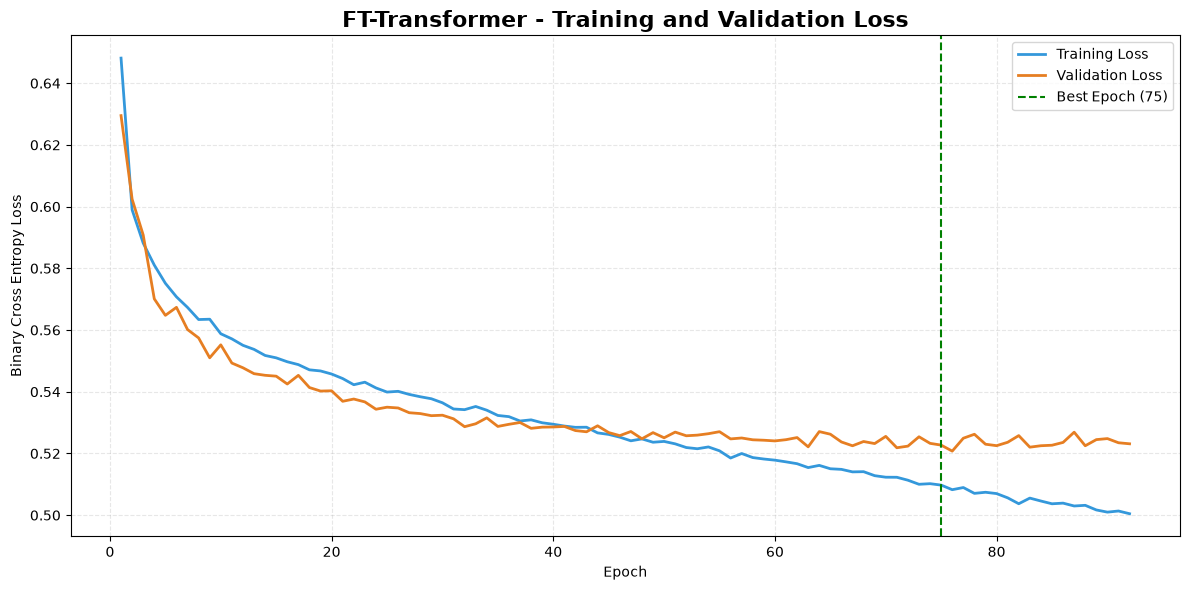

In [50]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    HISTORY_DF["epoch"],
    HISTORY_DF["train_loss"],
    color="#3498db",
    linewidth=2,
    label="Training Loss"
)

ax.plot(
    HISTORY_DF["epoch"],
    HISTORY_DF["val_loss"],
    color="#e67e22",
    linewidth=2,
    label="Validation Loss"
)

ax.axvline(
    EARLY_STOPPING.best_epoch,
    color="green",
    linestyle="--",
    label=f"Best Epoch ({EARLY_STOPPING.best_epoch})"
)

ax.set_title(
    "FT-Transformer - Training and Validation Loss",
    fontsize=16,
    fontweight="bold"
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Binary Cross Entropy Loss")

ax.legend()
ax.grid(alpha=0.3, linestyle="--")

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "loss_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [51]:
BEST_CHECKPOINT = torch.load(
    CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=True
)

MODEL.load_state_dict(
    BEST_CHECKPOINT["model_state_dict"]
)

MODEL.eval()

FINAL_RESULTS = pd.DataFrame({
    "Train": evaluate("train"),
    "Validation": evaluate("val"),
    "Test": evaluate("test")
}).T

display(FINAL_RESULTS.round(6))

print(
    f"Final Test Accuracy: "
    f"{FINAL_RESULTS.loc['Test', 'accuracy'] * 100:.4f}%"
)

,loss,accuracy,roc_auc
Train,0.485795,0.758557,0.843279
Validation,0.522711,0.738463,0.817952
Test,0.533779,0.730240,0.809724


Final Test Accuracy: 73.0240%


In [53]:
import ast
import json
import torch
import joblib
import sklearn



MODEL_DIR = Path(
    "../models/higgs_small/ft_transformer/baseline/seed_0"
)

MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODEL_DIR / "ft_transformer_baseline.pth"
PREPROCESSING_PATH = MODEL_DIR / "preprocessing.joblib"
CONFIG_PATH = MODEL_DIR / "config.json"
ARCHITECTURE_PATH = MODEL_DIR / "model.py"

#  Restore Best CHECKPOINT

MODEL.load_state_dict(
    BEST_CHECKPOINT["model_state_dict"]
)

MODEL.eval()

#  Save Model


STATE_DICT = MODEL.state_dict()

for name, tensor in STATE_DICT.items():
    STATE_DICT[name] = tensor.detach().cpu()

torch.save(STATE_DICT, MODEL_PATH)

# Save Preprocessing

PREPROCESSING = {
    "train_means": TRAIN_MEANS,
    "normalizer": NORMALIZER,
    "feature_names": X_train.columns.tolist()
}

joblib.dump(PREPROCESSING, PREPROCESSING_PATH)

# Save Model Configuration

CONFIG = {
    "model_name": "original_ft_transformer",
    "dataset": "higgs_small",
    "seed": int(SEED),

    "d_numerical": int(X_train.shape[1]),
    "categories": None,
    "d_out": 1,

    "model_config": MODEL_CONFIG,

    "feature_names": X_train.columns.tolist(),

    "class_mapping": {
        "0": "Background",
        "1": "Signal"
    },

    "classification_threshold": 0.5,

    "best_epoch": int(BEST_CHECKPOINT["epoch"]),

    "test_accuracy": float(
        FINAL_RESULTS.loc["Test", "accuracy"]
    ),

    "test_roc_auc": float(
        FINAL_RESULTS.loc["Test", "roc_auc"]
    ),

    "total_parameters": sum(
        p.numel() for p in MODEL.parameters()
    ),

    "versions": {
        "torch": str(torch.__version__),
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "scikit-learn": sklearn.__version__,
        "joblib": joblib.__version__
    }
}

with CONFIG_PATH.open("w", encoding="utf-8") as file:
    json.dump(CONFIG, file, indent=4)

# Save Model Architecture

REQUIRED_DEFINITIONS = [
    "Tokenizer",
    "reglu",
    "geglu",
    "get_activation_fn",
    "get_nonglu_activation_fn",
    "MultiheadAttention",
    "Transformer"
]

definitions = {}

for cell_source in In:

    try:
        tree = ast.parse(cell_source)
    except SyntaxError:
        continue

    for node in tree.body:

        if isinstance(node, (ast.ClassDef, ast.FunctionDef)):

            if node.name in REQUIRED_DEFINITIONS:
                definitions[node.name] = ast.get_source_segment(
                    cell_source, node
                )

missing = set(REQUIRED_DEFINITIONS) - set(definitions)

if missing:
    raise RuntimeError(f"Missing definitions: {missing}")

MODEL_SOURCE = """
import math
import typing as ty

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.nn.init as nn_init

from torch import Tensor
"""

MODEL_SOURCE += "\n\n" + "\n\n".join(
    definitions[name]
    for name in REQUIRED_DEFINITIONS
)

# Validate architecture syntax
compile(MODEL_SOURCE, "model.py", "exec")

ARCHITECTURE_PATH.write_text(
    MODEL_SOURCE,
    encoding="utf-8"
)

# Export Summary

print("=" * 65)
print("FT-Transformer Model Export Completed")
print("=" * 65)

print(f"Model Directory : {MODEL_DIR.resolve()}")
print(f"Best Epoch      : {CONFIG['best_epoch']}")
print(f"Test Accuracy   : {CONFIG['test_accuracy'] * 100:.4f}%")
print(f"Parameters      : {CONFIG['total_parameters']:,}")

print("\nExported Files:")
print("-" * 65)

for path in [
    MODEL_PATH,
    PREPROCESSING_PATH,
    CONFIG_PATH,
    ARCHITECTURE_PATH
]:
    print(
        f"{path.name:<35}"
        f"{path.stat().st_size / 1024**2:>10.4f} MiB"
    )

print("-" * 65)
print("Model export completed successfully!")

FT-Transformer Model Export Completed
Model Directory : /home/racoon/Downloads/Deep-Tabular-project/models/higgs_small/ft_transformer/baseline/seed_0
Best Epoch      : 75
Test Accuracy   : 73.0240%
Parameters      : 1,603,481

Exported Files:
-----------------------------------------------------------------
ft_transformer_baseline.pth            6.1288 MiB
preprocessing.joblib                   0.2240 MiB
config.json                            0.0015 MiB
model.py                               0.0099 MiB
-----------------------------------------------------------------
Model export completed successfully!
